# Turnaround-slack scenario simulation and demonstration

# Day 5 - Turnaround-slack scenario demo

This notebook shows a one-step **what-if** for aircraft delay propagation. For each April flight pair, it compares the selected Random Forest's relative delay-risk score under the observed scheduled turnaround slack and under hypothetical **+15** and **+30 minute** buffers. A simple rule-based residual-delay calculation provides a transparent cross-check. A sample aircraft chain is shown as a timeline.

The model was selected using February validation, the threshold is locked at **0.4987978449**, and model fitting uses January-March only. April is used here for demonstration scenarios, not for tuning. Day 4 found that model probabilities are poorly calibrated; the notebook calls its outputs **scores**, not literal risk percentages.

**Scenario limits:** the dataset has no intervention outcomes. Adding slack may require moving a scheduled departure and may affect later flights, crew, gates, and runway capacity. This demo changes only one input feature and assumes the inbound delay, route, time, and actual operating conditions stay fixed. It is not a causal estimate, dispatch recommendation, or route optimizer.


In [1]:

from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "processed").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "data" / "processed").is_dir():
    raise FileNotFoundError("Open the notebook from the flight project folder.")
PAIR_PATH = ROOT / "data" / "processed" / "wn_aircraft_pairs_2026-01_to_2026-04.csv"
REPORT_DIR = ROOT / "reports" / "metrics"
ANALYSIS_DIR = ROOT / "reports" / "analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR = ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
THRESHOLD = 0.49879784491634016
BUFFER_MINUTES = [0, 15, 30]


## 1. Rebuild the locked model without changing its settings

## 1. Rebuild the locked model without changing its settings

The pipeline is recreated to keep the demo runnable from a fresh kernel. Preprocessing is fit only on January-March training records. The threshold is loaded from the saved February validation table and checked against the locked value.


In [2]:

pairs = pd.read_csv(PAIR_PATH, low_memory=False, parse_dates=["FLIGHT_DATE"])
pairs["FLIGHT_DATE"] = pd.to_datetime(pairs["FLIGHT_DATE"], errors="coerce")
pairs = pairs.dropna(subset=["FLIGHT_DATE", "DEP_DEL15"]).copy()
pairs["DEP_DEL15"] = pairs["DEP_DEL15"].astype(int)
validation = pd.read_csv(REPORT_DIR / "day3_model_validation_comparison.csv")
selected = validation.loc[validation["MODEL"].eq("Engineered random forest")]
if len(selected) != 1 or not np.isclose(float(selected.iloc[0]["SELECTED_THRESHOLD"]), THRESHOLD):
    raise ValueError("Scenario threshold does not match the locked February validation result.")

april_start = pd.Timestamp("2026-04-01")
train = pairs.loc[pairs["FLIGHT_DATE"] < april_start].copy()
april = pairs.loc[pairs["FLIGHT_DATE"] >= april_start].copy()
if train.empty or april.empty:
    raise ValueError("Expected January-March model-training rows and April scenario rows.")

numeric_features = [
    "PREV_ARR_DELAY_LOG1P", "SCHEDULED_SLACK_LOG1P", "SHORT_SLACK_LT_60",
    "PREV_DELAY_X_SHORT_SLACK", "DEPARTURE_HOUR_SIN", "DEPARTURE_HOUR_COS",
]
categorical_features = ["ORIGIN", "DEST", "DAY_OF_WEEK"]
model_features = numeric_features + categorical_features

def add_engineered_features(frame):
    out = frame.copy()
    prev_delay = pd.to_numeric(out["PREV_ARR_DELAY_MIN"], errors="coerce").clip(lower=0)
    slack = pd.to_numeric(out["SCHEDULED_TURNAROUND_SLACK_MIN"], errors="coerce").clip(lower=0)
    hour = pd.to_numeric(out["DEPARTURE_HOUR_LOCAL"], errors="coerce")
    out["PREV_ARR_DELAY_LOG1P"] = np.log1p(prev_delay)
    out["SCHEDULED_SLACK_LOG1P"] = np.log1p(slack)
    out["SHORT_SLACK_LT_60"] = (slack < 60).astype("int8")
    out["PREV_DELAY_X_SHORT_SLACK"] = out["PREV_ARR_DELAY_LOG1P"] * out["SHORT_SLACK_LT_60"]
    out["DEPARTURE_HOUR_SIN"] = np.sin(2 * np.pi * hour / 24)
    out["DEPARTURE_HOUR_COS"] = np.cos(2 * np.pi * hour / 24)
    return out

numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median"))])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50)),
])
preprocess = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", categorical_pipe, categorical_features),
], remainder="drop")
model = Pipeline([
    ("preprocess", preprocess),
    ("classifier", RandomForestClassifier(
        n_estimators=120, max_depth=14, min_samples_leaf=40,
        max_features="sqrt", class_weight="balanced_subsample",
        n_jobs=-1, random_state=42,
    )),
])
train_features = add_engineered_features(train)[model_features]
model.fit(train_features, train["DEP_DEL15"])
print("Training rows:",len(train),"April scenario rows:",len(april),"locked threshold:",THRESHOLD)


Training rows: 309576 April scenario rows: 114084 locked threshold: 0.49879784491634016


## 2. Compare baseline, +15, and +30 minute scenarios

## 2. Compare baseline, +15, and +30 minute scenarios

For each scenario, scheduled slack increases while all other model inputs stay fixed. The rule-based cross-check estimates residual inbound delay as `max(0, previous arrival delay - (scheduled slack + added buffer))`; it flags the next flight if the residual is at least 15 minutes. This rule is intentionally simple and is not a learned or causal model.


 EXTRA_SCHEDULED_SLACK_MIN  MEAN_MODEL_SCORE  MEDIAN_MODEL_SCORE  SHARE_SCORE_LOWER_THAN_BASELINE  SHARE_MODEL_ALERT_AT_LOCKED_THRESHOLD  MEAN_RULE_RESIDUAL_DELAY_MIN  SHARE_RULE_FLAGS_DELAYED  MODEL_RULE_AGREEMENT
                         0            0.4233              0.3209                           0.0000                                 0.2781                        1.5969                    0.0287                0.7504
                        15            0.3922              0.3199                           0.5898                                 0.2417                        1.0366                    0.0180                0.7758
                        30            0.3586              0.3258                           0.5502                                 0.1933                        0.7009                    0.0120                0.8176


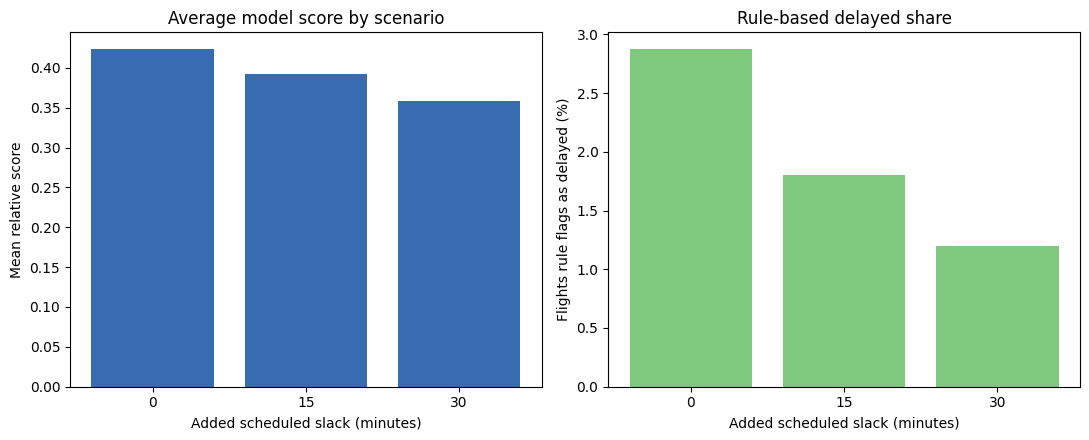

In [3]:

def scenario_frame(frame, extra_slack):
    scenario = frame.copy()
    scenario["SCHEDULED_TURNAROUND_SLACK_MIN"] = (
        pd.to_numeric(scenario["SCHEDULED_TURNAROUND_SLACK_MIN"], errors="coerce") + extra_slack
    )
    return add_engineered_features(scenario)

scenario_outputs = {}
scenario_summaries = []
for extra in BUFFER_MINUTES:
    frame = scenario_frame(april, extra)
    score = model.predict_proba(frame[model_features])[:, 1]
    residual = np.maximum(
        0,
        pd.to_numeric(april["PREV_ARR_DELAY_MIN"], errors="coerce").to_numpy()
        - (pd.to_numeric(april["SCHEDULED_TURNAROUND_SLACK_MIN"], errors="coerce").to_numpy() + extra),
    )
    rule_flag = (residual >= 15).astype(int)
    model_flag = (score >= THRESHOLD).astype(int)
    scenario_outputs[extra] = {
        "score": score,
        "rule_residual": residual,
        "rule_flag": rule_flag,
        "model_flag": model_flag,
    }
    baseline_score = scenario_outputs[0]["score"]
    scenario_summaries.append({
        "EXTRA_SCHEDULED_SLACK_MIN": extra,
        "MEAN_MODEL_SCORE": float(np.mean(score)),
        "MEDIAN_MODEL_SCORE": float(np.median(score)),
        "SHARE_SCORE_LOWER_THAN_BASELINE": float(np.mean(score < baseline_score - 1e-12)),
        "SHARE_MODEL_ALERT_AT_LOCKED_THRESHOLD": float(np.mean(model_flag)),
        "MEAN_RULE_RESIDUAL_DELAY_MIN": float(np.mean(residual)),
        "SHARE_RULE_FLAGS_DELAYED": float(np.mean(rule_flag)),
        "MODEL_RULE_AGREEMENT": float(np.mean(model_flag == rule_flag)),
    })

scenario_summary = pd.DataFrame(scenario_summaries)
scenario_summary.to_csv(REPORT_DIR / "day5_scenario_impact_summary.csv", index=False)
print(scenario_summary.to_string(index=False,float_format=lambda x:f"{x:.4f}"))

fig, axes = plt.subplots(1,2,figsize=(11,4.5))
axes[0].bar(scenario_summary["EXTRA_SCHEDULED_SLACK_MIN"].astype(str),scenario_summary["MEAN_MODEL_SCORE"],color="#386cb0")
axes[0].set(title="Average model score by scenario",xlabel="Added scheduled slack (minutes)",ylabel="Mean relative score")
axes[1].bar(scenario_summary["EXTRA_SCHEDULED_SLACK_MIN"].astype(str),100*scenario_summary["SHARE_RULE_FLAGS_DELAYED"],color="#7fc97f")
axes[1].set(title="Rule-based delayed share",xlabel="Added scheduled slack (minutes)",ylabel="Flights rule flags as delayed (%)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "day5_scenario_summary.png",dpi=160,bbox_inches="tight")
plt.show()


## 3. Select an illustrative aircraft chain and inspect scenarios

## 3. Pick an illustrative aircraft chain and inspect per-flight scenarios

For a concrete demo, choose an April tail with at least three linked pairs and at least one case with a late inbound aircraft and short scheduled slack. Among qualifying chains, the example is selected by average baseline model score, and the displayed four-flight window is centered on a qualifying case. This selection is only for visualization; it does not change the model or reported evaluation.


In [4]:

scenario_rows = []
for extra in BUFFER_MINUTES:
    out = scenario_outputs[extra]
    block = april[[
        "FLIGHT_DATE", "TAIL_NUM", "PREV_FLIGHT_DATE", "PREV_FLIGHT_NUM", "PREV_ORIGIN", "PREV_DEST",
        "PREV_ARR_DELAY_MIN", "SCHEDULED_TURNAROUND_SLACK_MIN", "FLIGHT_NUM", "ORIGIN", "DEST",
        "SCHEDULED_DEP_UTC", "ACTUAL_DEP_UTC", "DEP_DELAY_MIN", "DEP_DEL15",
    ]].copy()
    block["EXTRA_SCHEDULED_SLACK_MIN"] = extra
    block["MODEL_RELATIVE_SCORE"] = out["score"]
    block["MODEL_ALERT_AT_LOCKED_THRESHOLD"] = out["model_flag"]
    block["RULE_RESIDUAL_DELAY_MIN"] = out["rule_residual"]
    block["RULE_FLAGS_DELAYED"] = out["rule_flag"]
    scenario_rows.append(block)
all_scenario_rows = pd.concat(scenario_rows,ignore_index=True)

candidate = april.loc[
    (april["PREV_ARR_DELAY_MIN"] >= 30)
    & (april["SCHEDULED_TURNAROUND_SLACK_MIN"] <= 120)
].copy()
counts = candidate.groupby("TAIL_NUM").size()
eligible_tails = counts[counts >= 3].index
if len(eligible_tails)==0:
    counts = april.groupby("TAIL_NUM").size()
    eligible_tails = counts[counts >= 3].index
if len(eligible_tails)==0:
    raise ValueError("No April aircraft chain has three linked pairs for the timeline demo.")
base_scores = scenario_outputs[0]["score"]
score_series = pd.Series(base_scores,index=april.index)
tail_ranking = candidate.loc[candidate["TAIL_NUM"].isin(eligible_tails)].assign(_SCORE=score_series.loc[candidate.loc[candidate["TAIL_NUM"].isin(eligible_tails)].index]).groupby("TAIL_NUM")["_SCORE"].mean().sort_values(ascending=False)
demo_tail = tail_ranking.index[0]
tail_pairs = april.loc[april["TAIL_NUM"].eq(demo_tail)].sort_values(["FLIGHT_DATE","SCHEDULED_DEP_UTC"])
qualifying = tail_pairs.loc[
    (tail_pairs["PREV_ARR_DELAY_MIN"] >= 30)
    & (tail_pairs["SCHEDULED_TURNAROUND_SLACK_MIN"] <= 120)
].copy()
if not qualifying.empty:
    qualifying["_BASE_SCORE"] = score_series.loc[qualifying.index]
    anchor_index = qualifying.sort_values("_BASE_SCORE",ascending=False).index[0]
    anchor_position = tail_pairs.index.get_loc(anchor_index)
    start_position = max(0,anchor_position-1)
else:
    start_position = 0
demo_pairs = tail_pairs.iloc[start_position:start_position+4]
if len(demo_pairs)<3: demo_pairs=tail_pairs.head(4)
demo_index=demo_pairs.index
selected_flight_keys=demo_pairs[["FLIGHT_DATE","TAIL_NUM","FLIGHT_NUM"]].drop_duplicates()
chain_scenarios=all_scenario_rows.merge(selected_flight_keys,on=["FLIGHT_DATE","TAIL_NUM","FLIGHT_NUM"],how="inner")
chain_scenarios.to_csv(REPORT_DIR / "day5_demo_chain_scenarios.csv",index=False)
print("Illustrative tail:",demo_tail,"pairs shown:",len(demo_pairs))
print(chain_scenarios[["FLIGHT_DATE","PREV_ORIGIN","PREV_DEST","ORIGIN","DEST","PREV_ARR_DELAY_MIN","SCHEDULED_TURNAROUND_SLACK_MIN","EXTRA_SCHEDULED_SLACK_MIN","MODEL_RELATIVE_SCORE","MODEL_ALERT_AT_LOCKED_THRESHOLD","RULE_RESIDUAL_DELAY_MIN","RULE_FLAGS_DELAYED","DEP_DELAY_MIN"]].to_string(index=False,float_format=lambda x:f"{x:.2f}"))


Illustrative tail: N8804L pairs shown: 4
FLIGHT_DATE PREV_ORIGIN PREV_DEST ORIGIN DEST  PREV_ARR_DELAY_MIN  SCHEDULED_TURNAROUND_SLACK_MIN  EXTRA_SCHEDULED_SLACK_MIN  MODEL_RELATIVE_SCORE  MODEL_ALERT_AT_LOCKED_THRESHOLD  RULE_RESIDUAL_DELAY_MIN  RULE_FLAGS_DELAYED  DEP_DELAY_MIN
 2026-04-12         DTW       LAS    LAS  DAL               46.00                           40.00                          0                  0.91                                1                     6.00                   0          84.00
 2026-04-12         LAS       DAL    DAL  TPA               89.00                           45.00                          0                  0.92                                1                    44.00                   1          93.00
 2026-04-13         DAL       TPA    TPA  HOU               99.00                          330.00                          0                  0.26                                0                     0.00                   0           1.00

## 4. View the aircraft-chain timeline

## 4. View the chain timeline

The horizontal axis is minutes relative to each current flight's original scheduled departure. The previous aircraft arrival is positioned using the actual turnaround time; hypothetical schedule markers are placed at +15 and +30 minutes; the actual departure remains the observed event. These markers illustrate the schedule shift assumption only. They do not simulate a new actual departure time or downstream runway/aircraft schedules.


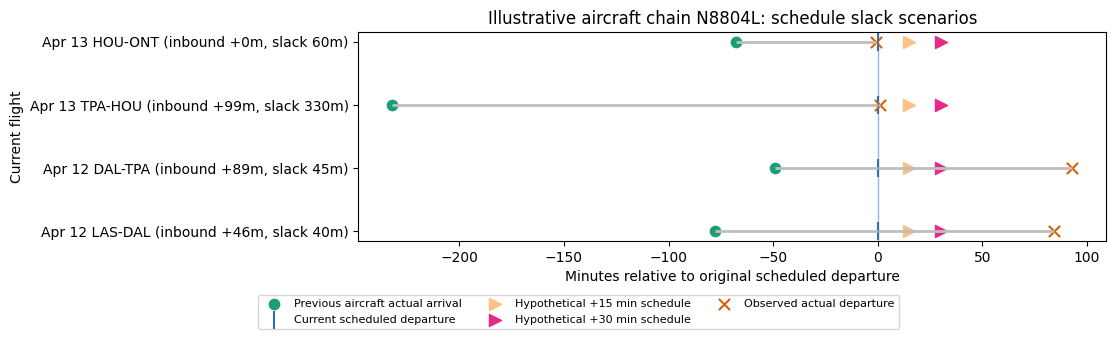

In [5]:

plot_pairs=demo_pairs.copy().reset_index(drop=True)
fig,ax=plt.subplots(figsize=(11,max(3.5,0.9*len(plot_pairs))))
for y,row in plot_pairs.iterrows():
    actual_turn=float(row["ACTUAL_TURNAROUND_MIN"])
    actual_delay=float(row["DEP_DELAY_MIN"])
    ax.hlines(y,-actual_turn,actual_delay,color="#bdbdbd",linewidth=2)
    ax.scatter(-actual_turn,y,marker="o",s=55,color="#1b9e77",label="Previous aircraft actual arrival" if y==0 else None)
    ax.scatter(0,y,marker="|",s=180,color="#386cb0",label="Current scheduled departure" if y==0 else None)
    ax.scatter(15,y,marker=">",s=75,color="#fdc086",label="Hypothetical +15 min schedule" if y==0 else None)
    ax.scatter(30,y,marker=">",s=75,color="#e7298a",label="Hypothetical +30 min schedule" if y==0 else None)
    ax.scatter(actual_delay,y,marker="x",s=65,color="#d95f02",label="Observed actual departure" if y==0 else None)
labels=[f"{r.FLIGHT_DATE:%b %d} {r.ORIGIN}-{r.DEST} (inbound +{r.PREV_ARR_DELAY_MIN:.0f}m, slack {r.SCHEDULED_TURNAROUND_SLACK_MIN:.0f}m)" for r in plot_pairs.itertuples()]
ax.set_yticks(range(len(plot_pairs)),labels)
ax.axvline(0,color="#386cb0",linewidth=1,alpha=.5)
ax.set(title=f"Illustrative aircraft chain {demo_tail}: schedule slack scenarios",xlabel="Minutes relative to original scheduled departure",ylabel="Current flight")
handles,legend_labels=ax.get_legend_handles_labels()
fig.legend(handles,legend_labels,loc="lower center",bbox_to_anchor=(0.5,0.02),ncol=3,fontsize=8)
fig.subplots_adjust(left=0.30,right=0.98,top=0.86,bottom=0.28)
fig.savefig(FIGURE_DIR / "day5_demo_chain_timeline.png",dpi=160,bbox_inches="tight")
plt.show()


## Scenario interpretation and assumptions

## Day 5 interpretation and assumptions

- The model score can go up or down under a feature-only slack change; it is not guaranteed to decrease monotonically. Trees learn observed associations, not intervention effects.
- The rule-based residual-delay estimate is transparent but omits recovery behavior, weather, gate/runway constraints, crew, aircraft swaps, and schedule interactions.
- The demo shifts only the current flight's planned slack. It does not test whether moving a departure is feasible, whether a runway slot is available, or how the change propagates to later flights.
- Because Day 4 found poor calibration, present score differences and threshold alerts as relative model signals rather than calibrated probabilities.


In [6]:

scenario_summary_json={
    "model":"Engineered Random Forest",
    "training_period":"January-March 2026",
    "scenario_demo_period":"April 2026",
    "threshold_from_february_validation":THRESHOLD,
    "scenario_buffers_min":BUFFER_MINUTES,
    "demonstration_tail":str(demo_tail),
    "scenario_assumptions":[
        "Only scheduled turnaround slack is increased; all other model inputs are held fixed.",
        "Rule residual is max(0, previous arrival delay - (scheduled slack + added buffer)).",
        "No causal/intervention data or downstream schedule effects are modeled.",
        "Model scores are not calibrated probabilities.",
    ],
    "population_scenario_summary":scenario_summary.to_dict(orient="records"),
    "outputs":[
        "reports/metrics/day5_scenario_impact_summary.csv",
        "reports/metrics/day5_demo_chain_scenarios.csv",
        "reports/figures/day5_scenario_summary.png",
        "reports/figures/day5_demo_chain_timeline.png",
        "reports/metrics/day5_run_summary.json",
        "reports/analysis/day5_scenario_notes.md",
    ],
}
(REPORT_DIR/"day5_run_summary.json").write_text(json.dumps(scenario_summary_json,indent=2),encoding="utf-8")
notes=[
"# Turnaround scenario notes", "",
f"Selected illustrative aircraft tail: `{demo_tail}`. The model threshold remains `{THRESHOLD:.4f}`, selected on February validation.", "",
"## Population scenario summary", "",
"| Added slack (min) | Mean relative model score | Share with lower score vs baseline | Model alerts at locked threshold | Rule flags delayed | Rule/model agreement |", "|---:|---:|---:|---:|---:|---:|",
]
for row in scenario_summary.itertuples(index=False):
 notes.append(f"| {row.EXTRA_SCHEDULED_SLACK_MIN:.0f} | {row.MEAN_MODEL_SCORE:.4f} | {row.SHARE_SCORE_LOWER_THAN_BASELINE:.1%} | {row.SHARE_MODEL_ALERT_AT_LOCKED_THRESHOLD:.1%} | {row.SHARE_RULE_FLAGS_DELAYED:.1%} | {row.MODEL_RULE_AGREEMENT:.1%} |")
notes += ["", "## Assumptions and limits", "", "The buffer is a feature-only what-if. It is not a causal estimate and does not establish that schedule changes are feasible or beneficial. Outputs are relative model scores, not calibrated risk probabilities. The transparent rule uses residual inbound delay after scheduled slack as a simple cross-check."]
(ANALYSIS_DIR/"day5_scenario_notes.md").write_text(chr(10).join(notes)+chr(10),encoding="utf-8")
print("Scenario notes and reports saved.")


Scenario notes and reports saved.
